# Capital Rentals

MATH 153 ~ Group Project ~ Team Members: Karma, Melvin, Risav, Shirjak

In [4]:
import json, re, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = "data/"

## Part 1. Concatenating datasets

### 1.1 – 1.3 Load, rename, convert, stack

In [5]:
q3 = pd.read_csv(DATA + "listings_q3.csv")
q4 = pd.read_csv(DATA + "listings_q4.csv")

# 1.1 rename Q4 columns to match Q3 exactly (positional order is identical, but we map by name to be explicit)
q4 = q4.rename(columns={
    "ListingID": "listing_id", "Landlord": "landlord_id", "Neighborhood": "nbhd",
    "Bedrooms": "beds", "Bathrooms": "baths", "SqFt": "sqft",
    "Monthly_Rent": "rent", "Date_Listed": "listed_on",
})
assert list(q3.columns) == list(q4.columns)

# 1.2 rent text -> float; dates -> datetime (explicit formats)
q4["rent"] = q4["rent"].str.replace(r"[$,]", "", regex=True).astype(float)
q3["listed_on"] = pd.to_datetime(q3["listed_on"], format="%Y-%m-%d")   # Q3 is ISO
q4["listed_on"] = pd.to_datetime(q4["listed_on"], format="%m/%d/%Y")   # Q4 is MM/DD/YYYY

# 1.3 source column + stack
q3["source"] = "q3"
q4["source"] = "q4"
stacked = pd.concat([q3, q4], ignore_index=True)
print("q3:", q3.shape, "| q4:", q4.shape, "| stacked:", stacked.shape)
stacked.dtypes

q3: (180, 9) | q4: (126, 9) | stacked: (306, 9)


listing_id                str
landlord_id               str
nbhd                      str
beds                    int64
baths                 float64
sqft                  float64
rent                  float64
listed_on      datetime64[us]
source                    str
dtype: object

**Formats used:** Q3 dates format="%Y-%m-%d", Q4 dates format="%m/%d/%Y". Rent in Q4 was text like `"$4,290"`; we strip `$` and `,` with a regex, then cast to float.

### 1.4 Duplicates (re-posted listings)

In [6]:
dups = stacked[stacked["listing_id"].duplicated(keep=False)].sort_values(["listing_id", "source"])
display(dups)

# To find if the two copies identical apart from 'source'?
cols = [c for c in stacked.columns if c != "source"]
print("Re-posted IDs:", dups["listing_id"].nunique())
print("Copies identical on all other columns:", dups.groupby("listing_id")[cols].nunique().max().max() == 1)

before = len(stacked)
# keep the Q4 copy (the most recent posting). Since copies are identical it makes no numeric difference,
# but the latest posting is the right default if they ever differed.
listings = (stacked.sort_values(["listing_id", "listed_on", "source"])
                   .drop_duplicates("listing_id", keep="last")
                   .sort_values("listing_id").reset_index(drop=True))
print(f"rows before: {before} | rows after: {len(listings)} | removed: {before - len(listings)}")

,listing_id,landlord_id,nbhd,beds,baths,sqft,rent,listed_on,source
36,R-10037,LL123,N11,0,1.0,340.0,1560.0,2026-07-14,q3
303,R-10037,LL123,N11,0,1.0,340.0,1560.0,2026-07-14,q4
126,R-10127,LL121,Nbhd 08,1,1.0,650.0,2740.0,2026-09-18,q3
271,R-10127,LL121,Nbhd 08,1,1.0,650.0,2740.0,2026-09-18,q4
133,R-10134,LL106,n-05,1,1.0,690.0,2430.0,2026-09-18,q3
219,R-10134,LL106,n-05,1,1.0,690.0,2430.0,2026-09-18,q4
138,R-10139,LL114,N04,1,1.0,870.0,3040.0,2026-09-18,q3
251,R-10139,LL114,N04,1,1.0,870.0,3040.0,2026-09-18,q4
143,R-10144,LL109,n10,4,2.0,1720.0,5990.0,2026-09-20,q3
252,R-10144,LL109,n10,4,2.0,1720.0,5990.0,2026-09-20,q4


Re-posted IDs: 6
Copies identical on all other columns: True
rows before: 306 | rows after: 300 | removed: 6


**Finding:** Every re-posted listing is an exact copy (same landlord, rent, date), so which one we keep does not change any number. We keep the later (Q4) copy by convention. Leaving duplicates in would double-count those listings in every average and in the SQL counts.

## Part 2. Regular expressions

### 2.1 Cleaning the neighborhood code

In [7]:
spellings = sorted(listings["nbhd"].unique(), key=lambda s: (s.strip().lower().replace("-", "").replace(" ", "")))
print(len(spellings), "distinct raw spellings:")
print([repr(s) for s in spellings])

59 distinct raw spellings:
["'N01'", "'n01'", "'n-01'", "'N02'", "'n02'", "'n-02'", "'N03'", "'n-03'", "'n03'", "'N04'", "'n-04'", "'n04'", "'n05'", "'N05'", "'n-05'", "'N06'", "'n-06'", "'N07'", "'n07'", "'n-07'", "'n08'", "'N08'", "'n-08'", "'n09'", "'n-09'", "'N09'", "' N1 '", "'n-10'", "' N10 '", "'N10'", "'n10'", "'n-11'", "'N11'", "' N11 '", "'n11'", "'n12'", "'N12'", "'n-12'", "' N12 '", "' N2 '", "' N3 '", "' N4 '", "' N5 '", "' N6 '", "' N7 '", "' N8 '", "' N9 '", "'Nbhd 01'", "'Nbhd 02'", "'Nbhd 03'", "'Nbhd 04'", "'Nbhd 05'", "'Nbhd 06'", "'Nbhd 07'", "'Nbhd 08'", "'Nbhd 09'", "'Nbhd 10'", "'Nbhd 11'", "'Nbhd 12'"]


In [8]:
# One regex: optional spaces, N/n, optional 'bhd', optional space/hyphen, optional leading 0, 1-2 digits, optional spaces.
NBHD_RE = r"^\s*[Nn](?:bhd)?[\s-]*0?(\d{1,2})\s*$"
listings["nbhd_code"] = listings["nbhd"].str.replace(NBHD_RE, lambda m: f"N{int(m.group(1)):02d}", regex=True)
codes = sorted(listings["nbhd_code"].unique())
print(len(codes), codes)
assert len(codes) == 12 and all(re.fullmatch(r"N(0[1-9]|1[0-2])", c) for c in codes)

12 ['N01', 'N02', 'N03', 'N04', 'N05', 'N06', 'N07', 'N08', 'N09', 'N10', 'N11', 'N12']


**Pattern explained:** `^\s*` allows leading spaces; `[Nn]` the letter; `(?:bhd)?` the optional word "bhd" (non-capturing); `[\s-]*` any mix of spaces/hyphens; `0?` an optional leading zero; `(\d{1,2})` captures the number (1 or 2 digits); `\s*$` trailing spaces. The replacement function re-pads the captured number to two digits and puts `N` in front. The assertion proves exactly 12 valid codes (N01–N12) remain.

### 2.2 Parsing raw_ads.txt

In [9]:
PATTERNS = {
    # R- followed by exactly five digits
    "listing_id": r"R-\d{5}",
    # a number (with optional thousands commas) followed by sq ft / sqft / sq.ft. / SF  (case-insensitive)
    "sqft": r"(\d{1,3}(?:,\d{3})+|\d+)\s*(?:sq\.?\s*ft\.?|sqft|SF)\b",
    # dollar sign then digits with optional thousands commas
    "rent": r"\$(\d{1,3}(?:,\d{3})+|\d+)",
    # (ddd) ddd-dddd
    "phone": r"\(\d{3}\)\s*\d{3}-\d{4}",
    # local@domain.tld
    "email": r"[\w.+-]+@[\w-]+(?:\.[\w-]+)*\.[a-z]{2,}",
}

def first(pattern, line, group=0):
    m = re.search(pattern, line, flags=re.IGNORECASE)
    return m.group(group) if m else None

rows = []
with open(DATA + "raw_ads.txt", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        sq, rent = first(PATTERNS["sqft"], line, 1), first(PATTERNS["rent"], line, 1)
        rows.append({
            "listing_id": first(PATTERNS["listing_id"], line),
            "ad_sqft": float(sq.replace(",", "")) if sq else np.nan,
            "ad_rent": float(rent.replace(",", "")) if rent else np.nan,
            "ad_phone": first(PATTERNS["phone"], line),
            "ad_email": first(PATTERNS["email"], line),
        })
ads = pd.DataFrame(rows)
print(ads.shape)
display(ads.head(10))
print(ads.isna().sum())

(32, 5)


,listing_id,ad_sqft,ad_rent,ad_phone,ad_email
0,R-10274,1880.0,6490.0,(301) 555-1370,potomacpropertygroup@rentals.net
1,R-10140,1170.0,2120.0,(202) 555-1185,anacostiahomes@rentals.net
2,R-10155,770.0,2610.0,(240) 555-1407,luis.ortiz@mail.com
3,R-10275,360.0,1520.0,NaN,hassan.karim@mail.com
4,R-10247,1260.0,5910.0,(301) 555-1555,capitolkeys@rentals.net
5,R-10291,780.0,2930.0,(301) 555-1814,NaN
6,R-10235,1690.0,6850.0,NaN,northstarrentals@rentals.net
7,R-10128,1440.0,2840.0,(240) 555-1629,rosa.alvarez@mail.com
8,R-10111,1750.0,3410.0,(301) 555-1222,gloria.diallo@mail.com
9,R-10182,1200.0,2760.0,(301) 555-1333,jamal.wright@mail.com


listing_id    0
ad_sqft       0
ad_rent       0
ad_phone      6
ad_email      9
dtype: int64


**What each pattern does**
- `listing_id` `R-\d{5}`: literal `R-` and exactly five digits.
- `sqft` `(\d{1,3}(?:,\d{3})+|\d+)\s*(?:sq\.?\s*ft\.?|sqft|SF)\b`: captures either a comma-grouped number (`1,260`) or a plain number, then optional space, then any of `sq ft`, `sq.ft.`, `sqft`, `SF`. Case-insensitive; `\b` stops it matching inside longer words.
- `rent` `\$(...)`: the number after a dollar sign, same comma handling. Works for `$6,490 per month`, `$1,520/month`, `$2,930.`
- `phone` `\(\d{3}\)\s*\d{3}-\d{4}`: area code in literal parentheses.
- `email`: word characters/dots before `@`, domain labels, and a final TLD of 2+ letters. Because the TLD must be letters, a sentence-ending period (`...mail.com.`) is not swallowed.

Phone and email are legitimately missing in some ads (some give only one contact method), so those NaNs are expected.

### 2.3 Merge ads onto listings, check rent, fill sqft

In [10]:
merged = listings.merge(ads, on="listing_id", how="outer", indicator=True)
print(merged["_merge"].value_counts())

both = merged[merged["_merge"] == "both"]
print("\nmatched rows:", len(both))
print("rent disagreements (ad_rent vs rent):", (both["ad_rent"] != both["rent"]).sum())
print("ads that had a sqft where listing ALSO had a sqft:", both["sqft"].notna().sum(),
      "| of those, conflicting:", (both["sqft"].notna() & (both["sqft"] != both["ad_sqft"])).sum())

missing_before = listings["sqft"].isna().sum()
listings = listings.merge(ads, on="listing_id", how="left")
listings["sqft"] = listings["sqft"].fillna(listings["ad_sqft"])
missing_after = listings["sqft"].isna().sum()
print(f"\nsqft missing before: {missing_before} | after: {missing_after}")

_merge
left_only     268
both           32
right_only      0
Name: count, dtype: int64

matched rows: 32
rent disagreements (ad_rent vs rent): 0
ads that had a sqft where listing ALSO had a sqft: 0 | of those, conflicting: 0

sqft missing before: 32 | after: 0


**Finding:** The ads agree with the CSV rent on every matched row, so they are a trustworthy second source. They exist exactly for the listings that have no square footage in the CSVs, so `fillna` with `ad_sqft` fills every gap.

### Part 3. Joining and Merging

**3.1 Flatten and identify columns from nested contact. Add a column counting each landlords's licenses**

The small setup below joins the registry and neighborhood names to create master for this analysis. All statistical standard deviations use the sample standard deviation (ddof=1), consistently for detection, masking, and standardization. Outlier flags are review signals, not proof of errors. Raw values are preserved; uncertain corrections are not invented.

In [11]:
import json
import pandas as pd

with open(DATA + "landlords.json", encoding="utf-8") as f:
    registry = json.load(f)

# Flatten the landlords list
landlords_flat = pd.json_normalize(registry["landlords"])

# Columns that came from the nested contact object
contact_cols = [col for col in landlords_flat.columns
                if col.startswith("contact.")]

print("Contact columns:", contact_cols)

# Count licenses for each landlord
landlords_flat["n_licenses"] = landlords_flat["licenses"].apply(len)

landlords_flat.head()

Contact columns: ['contact.phone', 'contact.email']


,landlord_id,name,type,rating,licenses,since,contact.phone,contact.email,n_licenses
0,LL101,Rock Creek Realty,company,4.8,[DC-BBL-139193],2016,(240) 555-1000,rockcreekrealty@rentals.net,1
1,LL102,Brian Brooks,individual,2.9,"[DC-BBL-992913, DC-BBL-534276]",2014,(703) 555-1037,brian.brooks@mail.com,2
2,LL103,Chidi Okafor,individual,4.6,[DC-BBL-357069],2018,(703) 555-1074,chidi.okafor@mail.com,1
3,LL104,Dana Reyes,individual,4.8,"[DC-BBL-726230, DC-BBL-316405]",2011,(703) 555-1111,dana.reyes@mail.com,2
4,LL105,Efua Asante,individual,3.5,[DC-BBL-541663],2022,(301) 555-1148,efua.asante@mail.com,1


In [12]:
from pathlib import Path
from IPython.display import display

with open(DATA + "landlords.json", encoding="utf-8") as f:
    registry = json.load(f)
landlords = pd.json_normalize(registry["landlords"])
landlords["n_licenses"] = landlords["licenses"].str.len()
neighborhoods = pd.read_csv(DATA + "neighborhoods.csv")
master = (listings.merge(landlords, on="landlord_id", how="left", validate="many_to_one")
          .merge(neighborhoods, on="nbhd_code", how="left", validate="many_to_one"))
assert len(master) == len(listings) == 300
assert master["listing_id"].is_unique
assert master["nbhd_name"].notna().all()
print(f"Master dataset: {master.shape[0]} listings, {master.shape[1]} columns")
uncleaned = master.copy(deep=True)

Master dataset: 300 listings, 25 columns


**3.2 Outer merge of listings and landlords, reporting the counts of both, left_only, and right_only, and identify the IDs of each unmatched group. Explain whe each unmatched group means for the nonprofit**

In [13]:
# Outer merge with merge indicator
merged = listings.merge(
    landlords_flat,
    on="landlord_id",
    how="outer",
    indicator=True
)

# Count records in each merge category
print("Merge Counts:")
print(merged["_merge"].value_counts())
print()

# Get unmatched landlord IDs
left_ids = (
    merged.loc[merged["_merge"] == "left_only", "landlord_id"]
    .dropna()
    .unique()
    .tolist()
)

right_ids = (
    merged.loc[merged["_merge"] == "right_only", "landlord_id"]
    .dropna()
    .unique()
    .tolist()
)

print("Left-only landlord IDs:")
print(left_ids)
print()

print("Right-only landlord IDs:")
print(right_ids)
print()


Merge Counts:
_merge
both          297
left_only       3
right_only      1
Name: count, dtype: int64

Left-only landlord IDs:
['LL199']

Right-only landlord IDs:
['LL125']



1. both: The landlord_id appears in both listings and landlords. These are valid matches.
2. left_only: The landlord_id appears in listings but not in landlords.
   - This means that there are rental listings whose landlord cannot be found in the landlord registry, possibly indicating missing registry data, entry errors, or unregistered landlords
4. right_only: The landlord_id appears in landlords but not in listings.
   - This means that there are landlords in the registry who currently have no matching listings in the listings dataset. These may be landlords who own properties that are not listed, or the listings dataset might be incomplete.

**3.3 Compare an inner and a left merge of the same two tables. How many listings does each keep, and which one should the nonprofit use?**

In [14]:
# Inner merge
inner_merged = listings.merge(
    landlords_flat,
    on="landlord_id",
    how="inner"
)

# Left merge
left_merged = listings.merge(
    landlords_flat,
    on="landlord_id",
    how="left"
)

print("Inner merge listings:", len(inner_merged))
print("Left merge listings:", len(left_merged))

Inner merge listings: 297
Left merge listings: 300


Inner merge keeps 297 listings and left merge keeps 300 listings. Based on these findings, the nonprofit should generally use the left merge because it preserves all listings in the dataset, including listings whose landlord information is missing from the registry. 

**3.4 Merge the neighborhood table onto the result and explain what validate protects you from.**

In [15]:
neighborhoods = pd.read_csv(DATA + "neighborhoods.csv")

In [16]:
# Merge neighborhood onto the left-merged data
master_dataset = left_merged.merge(
    neighborhoods,
    on="nbhd_code",
    how="left",
    validate="many_to_one"
)

master_dataset.head()

,listing_id,landlord_id,nbhd,beds,baths,sqft,rent,listed_on,source,nbhd_code,...,type,rating,licenses,since,contact.phone,contact.email,n_licenses,nbhd_name,ward,median_income
0,R-10001,LL104,N07,1,1.0,890.0,1450.0,2026-07-21,q3,N07,...,individual,4.8,"[DC-BBL-726230, DC-BBL-316405]",2011.0,(703) 555-1111,dana.reyes@mail.com,2.0,Anacostia,8,41000
1,R-10002,LL117,n08,2,1.0,1230.0,4460.0,2026-07-08,q3,N08,...,individual,4.4,[DC-BBL-621267],2021.0,(301) 555-1592,quinn.nguyen@mail.com,1.0,Georgetown,2,171000
2,R-10003,LL124,N04,0,1.0,380.0,1590.0,2026-07-01,q3,N04,...,individual,3.2,[DC-BBL-224709],2021.0,(202) 555-1851,xavier.pierce@mail.com,1.0,Navy Yard,6,152000
3,R-10004,LL115,N02,3,1.5,1520.0,4440.0,2026-07-09,q3,N02,...,individual,3.1,"[DC-BBL-472555, DC-BBL-675959]",2018.0,(703) 555-1518,olu.bello@mail.com,2.0,Columbia Heights,1,97000
4,R-10005,LL124,Nbhd 09,0,1.0,350.0,1280.0,2026-07-10,q3,N09,...,individual,3.2,[DC-BBL-224709],2021.0,(202) 555-1851,xavier.pierce@mail.com,1.0,Adams Morgan,1,112000


validate="many_to_one" checks if the left table can have many rows with the same neighborhood and if the right table must have only one row per neighborhood. It protects against duplicate matches that would multiply rows. 

### Part 4. Reshaping

**4.1 Use melt to make change to a long format. Convert month to a real date, and report both shapes and explain why the long form has the number of rows it does**

In [17]:
rent_index_wide = pd.read_csv(DATA + "rent_index_wide.csv")

# Original shape
print("Wide shape:", rent_index_wide.shape)

# Convert wide -> long
rent_index_long = rent_index_wide.melt(
    id_vars="nbhd_name",
    var_name="month",
    value_name="index"
)

# Convert month to datetime
rent_index_long["month"] = pd.to_datetime(
    rent_index_long["month"],
    format="%b-%Y"
)

# New shape
print("Long shape:", rent_index_long.shape)

rent_index_long.head()

Wide shape: (12, 11)
Long shape: (120, 3)


,nbhd_name,month,index
0,Shaw,2026-01-01,104.4
1,Columbia Heights,2026-01-01,97.1
2,Petworth,2026-01-01,98.5
3,Navy Yard,2026-01-01,103.0
4,Capitol Hill,2026-01-01,102.4


The long form has that many rows because the general rule is Long = (# of neighborhoods) x (# of month columns). 

**4.2 Pivot the long table back to wide. Compute each neighborhood's percent change in the index from January to October, and rank the neighborhoods**

In [18]:
# Pivot bact to wide
rent_index_wide2 = rent_index_long.pivot(
    index="nbhd_name",
    columns="month",
    values="index"
)

# Check available columns and calculate
jan = pd.Timestamp("2026-01-01")
octo = pd.Timestamp("2026-10-01")

rent_index_wide2["pct_change"] = (
    (rent_index_wide2[octo] - rent_index_wide2[jan])
    / rent_index_wide2[jan]
    * 100
)

# Rank neighborhoods
ranking = (
    rent_index_wide2["pct_change"].sort_values(ascending=False).reset_index())

print(ranking)

           nbhd_name  pct_change
0           Petworth    7.512690
1       Adams Morgan    4.733728
2          Navy Yard    3.009709
3               Shaw    2.298851
4               NoMa    2.034588
5           U Street    0.828157
6   Columbia Heights    0.308960
7         Georgetown    0.098232
8          Brookland   -0.966184
9   Congress Heights   -2.140078
10      Capitol Hill   -5.175781
11         Anacostia   -5.263158


**4.3 From the master dataset, build a pivot_table of median rent by neighborhood and number of bedrooms. Explain why the median is a better choice than the mean and why some cells show NaN.**

In [19]:
# Pivot master_dataset
rent_pivot = master_dataset.pivot_table(
    values="rent",
    index="nbhd_name",
    columns="beds",
    aggfunc="median"
)

rent_pivot

beds,0,1,2,3,4
nbhd_name,,,,,
Adams Morgan,1500.0,2160.0,3620.0,5150.0,6190.0
Anacostia,915.0,1410.0,2165.0,2880.0,3445.0
Brookland,960.0,2010.0,2950.0,3320.0,NaN
Capitol Hill,1510.0,2620.0,3500.0,5780.0,6540.0
Columbia Heights,840.0,2440.0,3620.0,4485.0,4750.0
Congress Heights,1020.0,1305.0,1880.0,2660.0,2590.0
Georgetown,2040.0,3165.0,4460.0,5650.0,7200.0
Navy Yard,1640.0,2820.0,4245.0,6200.0,NaN
NoMa,1560.0,3080.0,3890.0,5750.0,5470.0


The median is prefered over the mean because rental prices often contain outliers. The median is more robust to these extreme values and better reflects a typical rent. The reason some cells contain NaN is because the dataset has no listings for that particular neighborhood and bedroom-count combination.

### Part 5 Part 5. Outliers: z-score, modified z-score, IQR

### 5.1 Validity first

Check physical/domain constraints before computing statistics. An apartment must have positive rent and floor area; bedrooms must be a nonnegative integer (0 means studio), and bathrooms must be positive. Missing/nonfinite values need reviewing. A zero floor area is impossible and would produce infinite rent per square foot. A statistical cutoff depends on the distribution and can miss zero or be distorted by extreme values; a domain rule does not.

In [20]:
numeric = master[["rent", "sqft", "beds", "baths"]]
validity_checks = pd.DataFrame({
    "missing_or_nonfinite": ~np.isfinite(numeric).all(axis=1),
    "nonpositive_rent": master["rent"].le(0),
    "nonpositive_sqft": master["sqft"].le(0),
    "invalid_beds": master["beds"].lt(0) | master["beds"].mod(1).ne(0),
    "nonpositive_baths": master["baths"].le(0),
}, index=master.index)
invalid_mask = validity_checks.any(axis=1)
invalid_rows = master.loc[invalid_mask].copy()
display(invalid_rows[["listing_id", "rent", "sqft", "beds", "baths"]])
display(validity_checks.sum().rename("rows_failing"))
print(f"Invalid rows: {invalid_mask.sum()}; usable for outlier calculations: {(~invalid_mask).sum()}")
# Quarantine invalid rows before division. Keep uncleaned unchanged for 6.3.
analysis = master.loc[~invalid_mask].copy()

,listing_id,rent,sqft,beds,baths
230,R-10231,2840.0,0.0,1,1.0


missing_or_nonfinite    0
nonpositive_rent        0
nonpositive_sqft        1
invalid_beds            0
nonpositive_baths       0
Name: rows_failing, dtype: int64

Invalid rows: 1; usable for outlier calculations: 299


**Findings:**

R-10231 has sqft = 0. Its rent is $2,840, so rent alone would not expose the invalid area. No matching ad supplies its true area; exclude this record from the cleaned analysis and preserve it in the audit trail.

### 5.2 Monthly rent per square foot

In [21]:
analysis["ppsf"] = analysis["rent"] / analysis["sqft"]
assert np.isfinite(analysis["ppsf"]).all()
display(analysis[["listing_id", "rent", "sqft", "ppsf"]].head())

,listing_id,rent,sqft,ppsf
0,R-10001,1450.0,890.0,1.629213
1,R-10002,4460.0,1230.0,3.626016
2,R-10003,1590.0,380.0,4.184211
3,R-10004,4440.0,1520.0,2.921053
4,R-10005,1280.0,350.0,3.657143


### 5.3 Compare three outlier rules

Compute all six sets of flags on the same 299 valid rows, before any statistical exclusions.

In [22]:
def outlier_rules(series):
    x = series.astype(float)
    if not np.isfinite(x).all():
        raise ValueError("Outlier calculations require finite values.")
    sd = x.std(ddof=1)
    median = x.median()
    mad = (x - median).abs().median()
    if sd == 0 or mad == 0:
        raise ValueError("SD/MAD is zero; the corresponding score is undefined.")
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    return pd.DataFrame({
        "z_score": ((x - x.mean()) / sd).abs().gt(3),
        "modified_z": (0.6745 * (x - median) / mad).abs().gt(3.5),
        "IQR": x.lt(q1 - 1.5 * iqr) | x.gt(q3 + 1.5 * iqr),
    }, index=x.index)

flags = pd.DataFrame(index=analysis.index)
comparison_rows = []
for column in ["rent", "ppsf"]:
    rules = outlier_rules(analysis[column])
    for rule in rules:
        flags[f"{column}_{rule}"] = rules[rule]
        ids = analysis.loc[rules[rule], "listing_id"].sort_values().tolist()
        comparison_rows.append({"column": column, "rule": rule,
                                "count": len(ids), "listing_ids": ", ".join(ids)})
comparison = pd.DataFrame(comparison_rows)
display(comparison)
analysis["rent_flag"] = flags.filter(like="rent_").any(axis=1)
analysis["ppsf_flag"] = flags.filter(like="ppsf_").any(axis=1)
display(analysis.loc[flags.any(axis=1),
                     ["listing_id", "nbhd_name", "beds", "baths", "rent", "sqft", "ppsf"]])

,column,rule,count,listing_ids
0,rent,z_score,1,R-10016
1,rent,modified_z,3,"R-10016, R-10119, R-10261"
2,rent,IQR,3,"R-10016, R-10119, R-10261"
3,ppsf,z_score,1,R-10016
4,ppsf,modified_z,3,"R-10016, R-10062, R-10141"
5,ppsf,IQR,4,"R-10016, R-10062, R-10119, R-10141"


,listing_id,nbhd_name,beds,baths,rent,sqft,ppsf
15,R-10016,Navy Yard,3,1.5,665000.0,1420.0,468.309859
61,R-10062,Petworth,2,2.0,2970.0,85.0,34.941176
118,R-10119,Georgetown,4,3.5,14800.0,2600.0,5.692308
140,R-10141,Shaw,1,1.0,27.5,670.0,0.041045
260,R-10261,Navy Yard,3,2.5,9900.0,1900.0,5.210526


### 5.4 Masking

A large observation pulls the mean upward and inflates the standard deviation used in the denominator. Other large rents then have smaller absolute z-scores and may be masked. Here, we would remove only the largest absolute rent z-score for this experiment; do not silently change the comparison in 5.3.

In [23]:
rent_z_before = (analysis["rent"] - analysis["rent"].mean()) / analysis["rent"].std(ddof=1)
extreme_index = rent_z_before.abs().idxmax()
extreme_id = analysis.loc[extreme_index, "listing_id"]
without_extreme = analysis.drop(index=extreme_index).copy()
rent_z_after = ((without_extreme["rent"] - without_extreme["rent"].mean())
                / without_extreme["rent"].std(ddof=1))
masking_summary = pd.DataFrame([
    {"sample": "Before", "n": len(analysis), "mean_rent": analysis["rent"].mean(),
     "sample_SD": analysis["rent"].std(ddof=1),
     "flagged_ids": ", ".join(analysis.loc[rent_z_before.abs().gt(3), "listing_id"])},
    {"sample": f"Without {extreme_id}", "n": len(without_extreme),
     "mean_rent": without_extreme["rent"].mean(),
     "sample_SD": without_extreme["rent"].std(ddof=1),
     "flagged_ids": ", ".join(without_extreme.loc[rent_z_after.abs().gt(3), "listing_id"])},
])
display(masking_summary.round(3))
before_ids = set(analysis.loc[rent_z_before.abs().gt(3), "listing_id"])
after_ids = set(without_extreme.loc[rent_z_after.abs().gt(3), "listing_id"])
print("Removed for masking experiment:", extreme_id)
print("Newly exposed IDs:", sorted(after_ids - before_ids))

,sample,n,mean_rent,sample_SD,flagged_ids
0,Before,299,5661.798,38299.299,R-10016
1,Without R-10016,298,3449.253,1771.018,"R-10119, R-10261"


Removed for masking experiment: R-10016
Newly exposed IDs: ['R-10119', 'R-10261']


**Findings:** 

Before removal, the mean rent is 5,661.80, and the sample standard deviation is 38,299.30; only R-10016 ($665,000) exceeds |z| = 3. After removing it, R-10119 and R-10261 exceed the threshold. The robust rules already identify those two on rent because their center and spread are less affected by the single enormous value.

### 5.5 Flagged on ppsf other than rent

In [24]:
ppsf_only = analysis.loc[analysis["ppsf_flag"] & ~analysis["rent_flag"],
                          ["listing_id", "beds", "rent", "sqft", "ppsf"]].copy()
diagnoses = {
    "R-10062": "85 sqft for 2 beds suggests an area entry/unit error; $2,970 rent is ordinary.",
    "R-10141": "$27.50 monthly rent suggests a decimal/unit error; area is ordinary; rent lower fences miss it.",
}
ppsf_only["diagnosis"] = ppsf_only["listing_id"].map(diagnoses)
assert ppsf_only["diagnosis"].notna().all()
display(ppsf_only)
rent_q1, rent_q3 = analysis["rent"].quantile([0.25, 0.75])
print("Rent IQR lower fence:", rent_q1 - 1.5 * (rent_q3 - rent_q1))
rent_mad = (analysis["rent"] - analysis["rent"].median()).abs().median()
print("Rent modified-z lower cutoff:", analysis["rent"].median() - 3.5 * rent_mad / 0.6745)

,listing_id,beds,rent,sqft,ppsf,diagnosis
61,R-10062,2,2970.0,85.0,34.941176,85 sqft for 2 beds suggests an area entry/unit...
140,R-10141,1,27.5,670.0,0.041045,$27.50 monthly rent suggests a decimal/unit er...


Rent IQR lower fence: -1490.0
Rent modified-z lower cutoff: -2894.9444032616757


**Interpretation:** 

R-10062 has ppsf about 34.94 because its recorded area is only 85 sqft. The numerator (2,970) looks ordinary, so rent-only checks miss the suspect denominator. R-10141 has ppsf about 0.041: its 27.50 rent is suspiciously low for a 670-sqft one-bedroom. The rent IQR and modified-z lower cutoffs are negative in this broad distribution, and its z-score is also small because the extreme high rent inflates the standard deviation. Dividing by area makes the low price stand out more clearly.

These features show inconsistencies that marginal checks miss; inspect both numerator and denominator and seek source confirmation before correcting.

### 5.6 Decisions and cleaned dataset

The audit below covers the union of all six statistical flags plus the invalid-area row. No matching ads supply verified corrections for the suspect rows. Exclude the three likely entry errors pending verification. Keep the two high-price listings as plausible luxury listings based on size, amenities, neighborhood, and finite ppsf; this is an explicit analytical judgment, not independent verification of the ads.

In [25]:
decision_notes = {
    "R-10231": ("remove", "Zero sqft is invalid; no source confirms the true area."),
    "R-10016": ("remove", "$665,000/month for 1,420 sqft is a likely entry error; correct rent is unverified."),
    "R-10062": ("remove", "85 sqft for two bedrooms is a likely area/unit error; correct area is unverified."),
    "R-10141": ("remove", "$27.50/month for a 670-sqft one-bedroom is a likely entry error; correct rent is unverified."),
    "R-10119": ("keep", "$14,800 for 2,600 sqft, four beds and 3.5 baths in Georgetown is plausible luxury housing."),
    "R-10261": ("keep", "$9,900 for 1,900 sqft, three beds and 2.5 baths in Navy Yard is high but plausible."),
}
review_ids = set(analysis.loc[flags.any(axis=1), "listing_id"]) | set(invalid_rows["listing_id"])
assert review_ids == set(decision_notes), "Every flagged/invalid row must have a decision."
audit = master.loc[master["listing_id"].isin(review_ids),
                   ["listing_id", "nbhd_name", "beds", "baths", "rent", "sqft"]].copy()
audit["decision"] = audit["listing_id"].map(lambda k: decision_notes[k][0])
audit["reason"] = audit["listing_id"].map(lambda k: decision_notes[k][1])
display(audit.sort_values("listing_id"))
remove_ids = set(audit.loc[audit["decision"].eq("remove"), "listing_id"])
cleaned = master.loc[~master["listing_id"].isin(remove_ids)].copy()
cleaned["ppsf"] = cleaned["rent"] / cleaned["sqft"]
assert len(cleaned) == 296
assert cleaned[["rent", "sqft"]].gt(0).all().all()
assert np.isfinite(cleaned[["rent", "sqft", "ppsf"]]).all().all()
print(f"Original unique listings: {len(master)}; removed: {len(remove_ids)}; retained: {len(cleaned)}")

,listing_id,nbhd_name,beds,baths,rent,sqft,decision,reason
15,R-10016,Navy Yard,3,1.5,665000.0,1420.0,remove,"$665,000/month for 1,420 sqft is a likely entr..."
61,R-10062,Petworth,2,2.0,2970.0,85.0,remove,85 sqft for two bedrooms is a likely area/unit...
118,R-10119,Georgetown,4,3.5,14800.0,2600.0,keep,"$14,800 for 2,600 sqft, four beds and 3.5 bath..."
140,R-10141,Shaw,1,1.0,27.5,670.0,remove,$27.50/month for a 670-sqft one-bedroom is a l...
230,R-10231,Columbia Heights,1,1.0,2840.0,0.0,remove,Zero sqft is invalid; no source confirms the t...
260,R-10261,Navy Yard,3,2.5,9900.0,1900.0,keep,"$9,900 for 1,900 sqft, three beds and 2.5 bath..."


Original unique listings: 300; removed: 4; retained: 296


### Part 6. Scaling and transformations

Keep original units alongside the new columns. Each transformation is fitted to the cleaned dataset. Standardization uses sample standard deviation (ddof=1) so the verification uses the same convention. These are descriptive transformations; for predictive modeling fit parameters on training data only.

In [26]:
transformed = cleaned.copy()
verification_rows = []
for column in ["rent", "sqft"]:
    x = cleaned[column]
    span = x.max() - x.min()
    sd = x.std(ddof=1)
    assert span > 0 and sd > 0
    transformed[f"{column}_minmax"] = (x - x.min()) / span
    transformed[f"{column}_standard"] = (x - x.mean()) / sd
    transformed[f"{column}_log1p"] = np.log1p(x)
    mm = transformed[f"{column}_minmax"]
    standardized = transformed[f"{column}_standard"]
    assert mm.between(0, 1).all()
    assert np.isclose(mm.min(), 0) and np.isclose(mm.max(), 1)
    assert np.isclose(standardized.mean(), 0, atol=1e-12)
    assert np.isclose(standardized.std(ddof=1), 1)
    verification_rows.append({"column": column, "minmax_min": mm.min(),
                              "minmax_max": mm.max(), "standard_mean": standardized.mean(),
                              "standard_sample_SD": standardized.std(ddof=1)})
verification = pd.DataFrame(verification_rows)
display(verification)
display(transformed[["listing_id", "rent", "rent_minmax", "rent_standard", "rent_log1p",
                     "sqft", "sqft_minmax", "sqft_standard", "sqft_log1p"]].head())

,column,minmax_min,minmax_max,standard_mean,standard_sample_SD
0,rent,0.0,1.0,-4.200844e-17,1.0
1,sqft,0.0,1.0,4.200844e-17,1.0


,listing_id,rent,rent_minmax,rent_standard,rent_log1p,sqft,sqft_minmax,sqft_standard,sqft_log1p
0,R-10001,1450.0,0.048468,-1.139841,7.280008,890.0,0.250000,-0.482195,6.792344
1,R-10002,4460.0,0.263008,0.565022,8.403128,1230.0,0.399123,0.301528,7.115582
2,R-10003,1590.0,0.058446,-1.060545,7.372118,380.0,0.026316,-1.657781,5.942799
3,R-10004,4440.0,0.261582,0.553694,8.398635,1520.0,0.526316,0.969998,7.327123
4,R-10005,1280.0,0.036351,-1.236128,7.155396,350.0,0.013158,-1.726933,5.860786


6.2 Skewness and side-by-side histograms

rent          1.311109
log1p_rent   -0.332478
Name: sample_skewness, dtype: float64

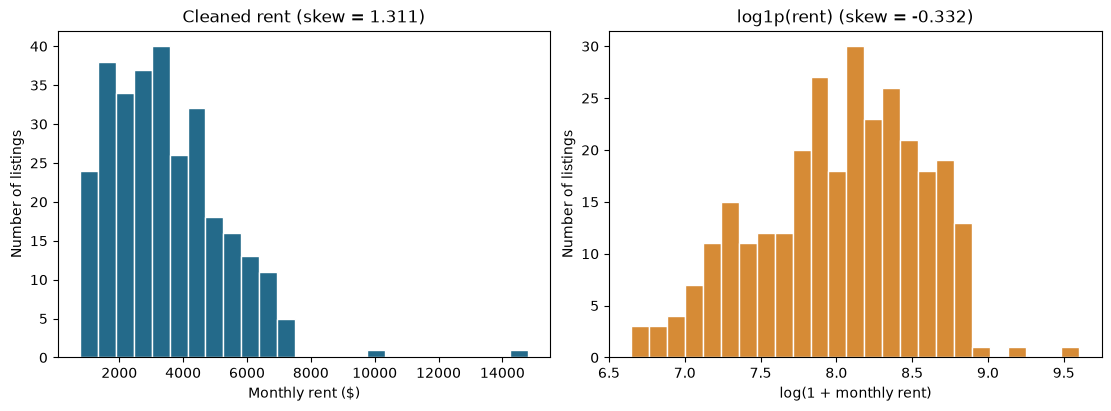

Skewness changes from 1.3111 to -0.3325.


In [27]:
skewness = pd.Series({"rent": cleaned["rent"].skew(),
                      "log1p_rent": transformed["rent_log1p"].skew()}, name="sample_skewness")
display(skewness)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].hist(cleaned["rent"], bins=25, color="#246a8a", edgecolor="white")
axes[0].set(title=f"Cleaned rent (skew = {skewness['rent']:.3f})",
            xlabel="Monthly rent ($)", ylabel="Number of listings")
axes[1].hist(transformed["rent_log1p"], bins=25, color="#d68b36", edgecolor="white")
axes[1].set(title=f"log1p(rent) (skew = {skewness['log1p_rent']:.3f})",
            xlabel="log(1 + monthly rent)", ylabel="Number of listings")
plt.show()
print(f"Skewness changes from {skewness['rent']:.4f} to {skewness['log1p_rent']:.4f}.")

I used log1p for this right-skewed price distribution when reducing the influence of its long upper tail is useful. It compresses large prices more than small ones and reduces skewness here. Min-max scaling and standardization are linear changes of units, so neither removes skewness. Log transformation need not produce a perfectly symmetric or normal distribution.

### 6.3 Scaling before versus after cleaning

Fit min-max scaling once on all 300 deduplicated, uncleaned rents (including the extremes), and once on the cleaned rents. Compare the same retained listings under both sets of scaling parameters so that row membership cannot explain the difference.

In [28]:
raw_rent = uncleaned["rent"]
raw_min, raw_max = raw_rent.min(), raw_rent.max()
uncleaned["rent_minmax_uncleaned"] = (raw_rent - raw_min) / (raw_max - raw_min)
scale_comparison = cleaned[["listing_id", "rent"]].copy()
scale_comparison["scaled_using_uncleaned"] = (cleaned["rent"] - raw_min) / (raw_max - raw_min)
scale_comparison["scaled_using_cleaned"] = transformed["rent_minmax"]
display(scale_comparison[["scaled_using_uncleaned", "scaled_using_cleaned"]]
        .quantile([0, 0.25, 0.5, 0.75, 0.95, 1]).rename_axis("quantile"))
display(scale_comparison.sort_values("rent").iloc[[0, len(scale_comparison)//2, -1]])
print(f"Uncleaned rent range: ${raw_min:,.2f} to ${raw_max:,.2f}")
print(f"Cleaned rent range: ${cleaned['rent'].min():,.2f} to ${cleaned['rent'].max():,.2f}")
print(f"Even the largest retained rent maps to only {scale_comparison['scaled_using_uncleaned'].max():.4f} using the uncleaned range.")

,scaled_using_uncleaned,scaled_using_cleaned
quantile,,
0.00,0.001117,0.000000
0.25,0.003158,0.096757
0.50,0.004906,0.179615
0.75,0.006775,0.268175
0.95,0.009726,0.408054
1.00,0.022215,1.000000


,listing_id,rent,scaled_using_uncleaned,scaled_using_cleaned
170,R-10171,770.0,0.001117,0.000000
80,R-10081,3300.0,0.004921,0.180328
118,R-10119,14800.0,0.022215,1.000000


Uncleaned rent range: $27.50 to $665,000.00
Cleaned rent range: $770.00 to $14,800.00
Even the largest retained rent maps to only 0.0222 using the uncleaned range.


**Finding:** 

The $665,000 maximum stretches the uncleaned range so much that ordinary listings cluster close to zero and useful differences are compressed. Even the highest retained rent maps to about 0.0222. Clean first, then estimate scaling parameters. Keeping plausible luxury listings still affects min-max scaling, but silently deleting real high prices just to improve a scale would distort the market.

6.4 Why log(1 + x)?
For nonnegative data, log1p(0) = 0, while log(0) is undefined (negative infinity in NumPy). In this project beds includes zeros for studios, so np.log1p(cleaned["beds"]) would retain them as finite values. This is an example of where the distinction matters, not a claim that bedroom counts need a log transform. NumPy's log1p is also more numerically accurate for tiny x. It is undefined for real-valued inputs below -1 and does not make negative or invalid measurements acceptable.

These files are generated inside results/ when the notebook is run. cleaned and transformed remain available for later project sections. The exports preserve original measurement values; the audit records every exclusion and reviewed retention.

In [29]:
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
cleaned.to_csv(results_dir / "listings_cleaned.csv", index=False)
transformed.to_csv(results_dir / "listings_transformed.csv", index=False)
audit.to_csv(results_dir / "cleaning_audit.csv", index=False)
comparison.to_csv(results_dir / "outlier_comparison.csv", index=False)
fig.savefig(results_dir / "rent_histograms.png", dpi=160, bbox_inches="tight")
print("Saved cleaned data, transformations, decisions, outlier comparison, and histogram figure to results/.")

Saved cleaned data, transformations, decisions, outlier comparison, and histogram figure to results/.


## Part 7. SQL: build and query a database

Part 7 works from `cleaned`, the 296 listings kept after 5.6, plus the 25 landlords in the registry and the 12 neighborhoods. Every value a query needs is passed in with a `?` placeholder.

### 7A. Build rentals.db

In [30]:
# 7A. Create rentals.db next to the notebook (relative path) with the three tables from the project sheet
con = sqlite3.connect("rentals.db")
con.execute("PRAGMA foreign_keys = ON")   # SQLite ignores FOREIGN KEY rules unless this is switched on

con.executescript("""
-- start from empty tables so the notebook can be run again without "table already exists" errors
DROP TABLE IF EXISTS listings;
DROP TABLE IF EXISTS landlords;
DROP TABLE IF EXISTS neighborhoods;

CREATE TABLE neighborhoods (
    nbhd_code     TEXT PRIMARY KEY,
    nbhd_name     TEXT NOT NULL,
    ward          INTEGER,
    median_income INTEGER
);

CREATE TABLE landlords (
    landlord_id TEXT PRIMARY KEY,
    name        TEXT NOT NULL,
    type        TEXT CHECK (type IN ('company', 'individual')),
    phone       TEXT,
    email       TEXT UNIQUE,
    rating      REAL CHECK (rating BETWEEN 0 AND 5),
    since       INTEGER
);

CREATE TABLE listings (
    listing_id  TEXT PRIMARY KEY,
    landlord_id TEXT,
    nbhd_code   TEXT NOT NULL,
    beds        INTEGER,
    baths       REAL,
    sqft        REAL,
    rent        REAL CHECK (rent > 0),
    listed_on   TEXT,
    FOREIGN KEY (nbhd_code) REFERENCES neighborhoods (nbhd_code)
);
""")
print("tables in rentals.db:", [name for (name,) in con.execute("SELECT name FROM sqlite_master WHERE type = 'table'")])

tables in rentals.db: ['neighborhoods', 'landlords', 'listings']


In [31]:
# One DataFrame per table, with the columns in the same order as the CREATE TABLE statements
nbhd_table = neighborhoods[["nbhd_code", "nbhd_name", "ward", "median_income"]]
landlord_table = (landlords.rename(columns={"contact.phone": "phone", "contact.email": "email"})
                  [["landlord_id", "name", "type", "phone", "email", "rating", "since"]])
listing_table = cleaned[["listing_id", "landlord_id", "nbhd_code", "beds", "baths",
                         "sqft", "rent", "listed_on"]].copy()
listing_table["listed_on"] = listing_table["listed_on"].dt.strftime("%Y-%m-%d")   # datetime to 'YYYY-MM-DD' text

# none of the three tables has a missing value, so no NULL gets into the database by accident
for table in [nbhd_table, landlord_table, listing_table]:
    assert table.notna().all().all()

# itertuples(index=False, name=None) gives plain Python tuples (int, float, str), which sqlite3 accepts
con.executemany("INSERT INTO neighborhoods VALUES (?, ?, ?, ?)",
                nbhd_table.itertuples(index=False, name=None))
con.executemany("INSERT INTO landlords VALUES (?, ?, ?, ?, ?, ?, ?)",
                landlord_table.itertuples(index=False, name=None))
con.executemany("INSERT INTO listings VALUES (?, ?, ?, ?, ?, ?, ?, ?)",
                listing_table.itertuples(index=False, name=None))
con.commit()

In [32]:
# PRAGMA table_info lists each column with its type, NOT NULL flag (notnull) and primary key flag (pk)
print("PRAGMA table_info(neighborhoods)")
display(pd.read_sql("PRAGMA table_info(neighborhoods)", con))
print("PRAGMA table_info(landlords)")
display(pd.read_sql("PRAGMA table_info(landlords)", con))
print("PRAGMA table_info(listings)")
display(pd.read_sql("PRAGMA table_info(listings)", con))
print("PRAGMA foreign_key_list(listings)")
display(pd.read_sql("PRAGMA foreign_key_list(listings)", con)[["table", "from", "to"]])

PRAGMA table_info(neighborhoods)


,cid,name,type,notnull,dflt_value,pk
0,0,nbhd_code,TEXT,0,None,1
1,1,nbhd_name,TEXT,1,None,0
2,2,ward,INTEGER,0,None,0
3,3,median_income,INTEGER,0,None,0


PRAGMA table_info(landlords)


,cid,name,type,notnull,dflt_value,pk
0,0,landlord_id,TEXT,0,None,1
1,1,name,TEXT,1,None,0
2,2,type,TEXT,0,None,0
3,3,phone,TEXT,0,None,0
4,4,email,TEXT,0,None,0
5,5,rating,REAL,0,None,0
6,6,since,INTEGER,0,None,0


PRAGMA table_info(listings)


,cid,name,type,notnull,dflt_value,pk
0,0,listing_id,TEXT,0,None,1
1,1,landlord_id,TEXT,0,None,0
2,2,nbhd_code,TEXT,1,None,0
3,3,beds,INTEGER,0,None,0
4,4,baths,REAL,0,None,0
5,5,sqft,REAL,0,None,0
6,6,rent,REAL,0,None,0
7,7,listed_on,TEXT,0,None,0


PRAGMA foreign_key_list(listings)


,table,from,to
0,neighborhoods,nbhd_code,nbhd_code


In [33]:
# Row counts in rentals.db next to the DataFrames they came from
row_check = pd.DataFrame({
    "table": ["neighborhoods", "landlords", "listings"],
    "rows_in_db": [con.execute("SELECT COUNT(*) FROM neighborhoods").fetchone()[0],
                   con.execute("SELECT COUNT(*) FROM landlords").fetchone()[0],
                   con.execute("SELECT COUNT(*) FROM listings").fetchone()[0]],
    "rows_in_dataframe": [len(nbhd_table), len(landlord_table), len(listing_table)],
})
display(row_check)
assert (row_check["rows_in_db"] == row_check["rows_in_dataframe"]).all()

# phone and listed_on come back as text, exactly as they went in
display(pd.read_sql("SELECT landlord_id, phone, typeof(phone) AS stored_as FROM landlords LIMIT 3", con))
display(pd.read_sql("SELECT listing_id, listed_on, typeof(listed_on) AS stored_as FROM listings LIMIT 3", con))

,table,rows_in_db,rows_in_dataframe
0,neighborhoods,12,12
1,landlords,25,25
2,listings,296,296


,landlord_id,phone,stored_as
0,LL101,(240) 555-1000,text
1,LL102,(703) 555-1037,text
2,LL103,(703) 555-1074,text


,listing_id,listed_on,stored_as
0,R-10001,2026-07-21,text
1,R-10002,2026-07-08,text
2,R-10003,2026-07-01,text


All three tables match their DataFrames: 12 neighborhoods, 25 landlords and 296 listings. Foreign keys were switched on during the insert, so any `nbhd_code` without a row in `neighborhoods` would have raised an error, and none did.

**Why phone is TEXT.** Nobody adds or averages phone numbers. An integer column would strip the brackets, space and dash out of `(202) 555-1185`, which is the exact text Q8 matches with `LIKE` to find the 202 numbers.

**Why dates are 'YYYY-MM-DD' text.** SQLite has no date type. With the year first, alphabetical order is the same as time order, so `ORDER BY` and `BETWEEN` work on the plain strings and SQLite's `date()` functions can read them. The `MM/DD/YYYY` style from `listings_q4.csv` would sort `01/15/2027` before `10/01/2026`.

#### Should listings.landlord_id also be a foreign key to landlords?

In [34]:
# Try it in a throwaway database in memory, so rentals.db stays exactly as built above
test = sqlite3.connect(":memory:")
test.execute("PRAGMA foreign_keys = ON")
test.executescript("""
CREATE TABLE landlords (landlord_id TEXT PRIMARY KEY, name TEXT NOT NULL, type TEXT,
                        phone TEXT, email TEXT UNIQUE, rating REAL, since INTEGER);
CREATE TABLE listings (listing_id TEXT PRIMARY KEY, landlord_id TEXT, nbhd_code TEXT NOT NULL,
                       beds INTEGER, baths REAL, sqft REAL, rent REAL, listed_on TEXT,
                       FOREIGN KEY (landlord_id) REFERENCES landlords (landlord_id));
""")
test.executemany("INSERT INTO landlords VALUES (?, ?, ?, ?, ?, ?, ?)",
                 landlord_table.itertuples(index=False, name=None))
test.commit()

try:
    test.executemany("INSERT INTO listings VALUES (?, ?, ?, ?, ?, ?, ?, ?)",
                     listing_table.itertuples(index=False, name=None))
except sqlite3.IntegrityError as err:
    print("executemany stopped:", err)
    print("rows already in the table when it stopped:", test.execute("SELECT COUNT(*) FROM listings").fetchone()[0])
    test.rollback()

# insert the listings one at a time to see every row the foreign key refuses
refused = []
for row in listing_table.itertuples(index=False, name=None):
    try:
        test.execute("INSERT INTO listings VALUES (?, ?, ?, ?, ?, ?, ?, ?)", row)
    except sqlite3.IntegrityError:
        refused.append(row)
print("rows accepted:", test.execute("SELECT COUNT(*) FROM listings").fetchone()[0], "| rows refused:", len(refused))
display(pd.DataFrame(refused, columns=listing_table.columns))
test.close()

executemany stopped: FOREIGN KEY constraint failed
rows already in the table when it stopped: 7
rows accepted: 293 | rows refused: 3


,listing_id,landlord_id,nbhd_code,beds,baths,sqft,rent,listed_on
0,R-10008,LL199,N12,2,1.5,1240.0,2280.0,2026-07-10
1,R-10089,LL199,N08,0,1.0,490.0,2550.0,2026-08-04
2,R-10202,LL199,N03,3,2.5,1230.0,4650.0,2026-10-10


No, not with this registry. With `foreign_keys` on, SQLite refused the three listings from landlord LL199: R-10008, R-10089 and R-10202. LL199 has no record in `landlords.json`. These are the `left_only` rows from the outer merge in 3.2. The plain `executemany` also gave up at R-10008, and by then the 7 rows before it were already in the table, which is why the cell rolls back before trying again row by row. Keeping the key would force us to delete three real listings or invent a registry entry for LL199, so we left `landlord_id` without a foreign key and list these listings with Q11 instead.

### 7B. Query the database

`run()` sends one query to `rentals.db` with its values as `?` parameters and returns the answer as a DataFrame, so each result prints as a table.

In [35]:
def run(sql, params=()):
    # run one query with ? placeholders and return the result as a DataFrame
    return pd.read_sql(sql, con, params=params)

#### Q1. The 10 most expensive listings

In [36]:
Q1 = """
SELECT listing_id, nbhd_code, beds, rent
FROM listings
ORDER BY rent DESC, listing_id   -- listing_id breaks any tie, so the top 10 is the same every run
LIMIT ?
"""
display(run(Q1, (10,)))

,listing_id,nbhd_code,beds,rent
0,R-10119,N08,4,14800.0
1,R-10261,N04,3,9900.0
2,R-10198,N11,3,7350.0
3,R-10125,N08,4,7200.0
4,R-10077,N05,4,7120.0
5,R-10034,N08,3,7030.0
6,R-10069,N09,4,7010.0
7,R-10234,N05,4,6930.0
8,R-10235,N10,4,6850.0
9,R-10179,N04,3,6740.0


Georgetown (N08) has 3 of the 10 most expensive listings, and all 10 have three or four bedrooms. At the top are R-10119 at \$14,800 and R-10261 at \$9,900, the two high rents kept in 5.6 as plausible luxury units.

#### Q2. Listings above \$5,000 and below \$1,500

In [37]:
Q2 = """
SELECT (SELECT COUNT(*) FROM listings WHERE rent > ?) AS over_5000,
       (SELECT COUNT(*) FROM listings WHERE rent < ?) AS under_1500
"""
display(run(Q2, (5000, 1500)))
# > and < are strict, so a rent of exactly 5,000 or 1,500 is not counted
print("rent exactly 5,000:", (listing_table["rent"] == 5000).sum(),
      "| rent exactly 1,500:", (listing_table["rent"] == 1500).sum())

,over_5000,under_1500
0,56,38


rent exactly 5,000: 1 | rent exactly 1,500: 1


56 of the 296 listings rent for more than \$5,000 (about 19%) and 38 for less than \$1,500 (about 13%). One listing sits at exactly \$5,000 and one at exactly \$1,500, and neither is counted because "more than" and "less than" are strict.

#### Q3. Two-bedroom listings under \$2,500

In [38]:
Q3 = """
SELECT listing_id, nbhd_code, beds, rent
FROM listings
WHERE beds = ? AND rent < ?
ORDER BY rent, listing_id
"""
q3 = run(Q3, (2, 2500))
print("two-bedroom listings under 2,500:", len(q3))
display(q3)

two-bedroom listings under 2,500: 18


,listing_id,nbhd_code,beds,rent
0,R-10169,N12,2,1660.0
1,R-10189,N07,2,1740.0
2,R-10115,N12,2,1760.0
3,R-10076,N07,2,1780.0
4,R-10242,N07,2,1780.0
5,R-10165,N12,2,1880.0
6,R-10073,N12,2,1900.0
7,R-10084,N07,2,2010.0
8,R-10045,N07,2,2090.0
9,R-10140,N07,2,2120.0


There are 18. Twelve are in Anacostia (N07) and five in Congress Heights (N12), both in Ward 8, and the one exception is R-10056 in Capitol Hill (N05) at \$2,360.

#### Q4. Listings in Anacostia (N07) or Congress Heights (N12)

In [39]:
Q4 = """
SELECT listing_id, nbhd_code, beds, rent
FROM listings
WHERE nbhd_code = ? OR nbhd_code = ?
ORDER BY listing_id
"""
q4 = run(Q4, ("N07", "N12"))
print("listings in N07 or N12:", len(q4))
print(q4["nbhd_code"].value_counts().to_string())
display(q4.head())

listings in N07 or N12: 51
nbhd_code
N07    31
N12    20


,listing_id,nbhd_code,beds,rent
0,R-10001,N07,1,1450.0
1,R-10008,N12,2,2280.0
2,R-10009,N12,1,1100.0
3,R-10012,N12,0,1020.0
4,R-10021,N07,1,1370.0


Between them the two neighborhoods have 51 listings, 31 in Anacostia and 20 in Congress Heights. They are also the two cheapest neighborhoods by average rent (see Q10).

#### Q5. Q4 rewritten with IN

In [40]:
Q5 = """
SELECT listing_id, nbhd_code, beds, rent
FROM listings
WHERE nbhd_code IN (?, ?)
ORDER BY listing_id
"""
q5 = run(Q5, ("N07", "N12"))
print("Q4 with OR:", len(q4), "rows | Q5 with IN:", len(q5), "rows")
assert q5.equals(q4)   # same rows in the same order

Q4 with OR: 51 rows | Q5 with IN: 51 rows


Same 51 listings. The assert compares the two result tables row by row, and `IN` is easier to read and to extend if the nonprofit wants more neighborhoods in the list.

#### Q6. Listings posted during August 2026

In [41]:
Q6 = """
SELECT listing_id, nbhd_code, rent, listed_on
FROM listings
WHERE listed_on BETWEEN ? AND ?
ORDER BY listed_on, listing_id
"""
q6 = run(Q6, ("2026-08-01", "2026-08-31"))
print("listings posted in August 2026:", len(q6),
      "| first date:", q6["listed_on"].min(), "| last date:", q6["listed_on"].max())
display(q6.head())
# why the dates were saved without a time: a timestamp on the afternoon of Aug 31 falls outside the range
print("'2026-08-31 14:00:00' BETWEEN '2026-08-01' AND '2026-08-31' gives:",
      con.execute("SELECT ? BETWEEN ? AND ?", ("2026-08-31 14:00:00", "2026-08-01", "2026-08-31")).fetchone()[0])

listings posted in August 2026: 61 | first date: 2026-08-01 | last date: 2026-08-22


,listing_id,nbhd_code,rent,listed_on
0,R-10104,N04,4200.0,2026-08-01
1,R-10060,N03,2100.0,2026-08-02
2,R-10065,N05,3260.0,2026-08-02
3,R-10077,N05,7120.0,2026-08-02
4,R-10102,N04,4170.0,2026-08-03


'2026-08-31 14:00:00' BETWEEN '2026-08-01' AND '2026-08-31' gives: 0


August 2026 has 61 listings. `BETWEEN` includes both end dates, and it works on text here because `listed_on` holds bare dates. The last line shows that a value with a time, like `'2026-08-31 14:00:00'`, sorts after `'2026-08-31'` and would be missed.

#### Q7. Listings that are neither studios nor one-bedrooms

In [42]:
Q7 = """
SELECT listing_id, nbhd_code, beds, rent
FROM listings
WHERE beds NOT IN (?, ?)
ORDER BY listing_id
"""
q7 = run(Q7, (0, 1))
print("listings with 2 or more bedrooms:", len(q7))
print(q7["beds"].value_counts().sort_index().to_string())
display(q7.head())

listings with 2 or more bedrooms: 180
beds
2    78
3    67
4    35


,listing_id,nbhd_code,beds,rent
0,R-10002,N08,2,4460.0
1,R-10004,N02,3,4440.0
2,R-10006,N09,2,3860.0
3,R-10008,N12,2,2280.0
4,R-10011,N04,2,4880.0


Of the 296 listings, 180 have two or more bedrooms: 78 with two, 67 with three and 35 with four. The other 116 are studios or one-bedrooms.

#### Q8. Landlords with an @rentals.net email, and landlords with a 202 phone number

In [43]:
Q8_EMAIL = """
SELECT landlord_id, name, type, email
FROM landlords
WHERE email LIKE ?
ORDER BY landlord_id
"""
Q8_PHONE = """
SELECT landlord_id, name, type, phone
FROM landlords
WHERE phone LIKE ?
ORDER BY landlord_id
"""
# % matches any run of characters: '%@rentals.net' = ends with @rentals.net, '(202)%' = starts with (202)
display(run(Q8_EMAIL, ("%@rentals.net",)))
display(run(Q8_PHONE, ("(202)%",)))

,landlord_id,name,type,email
0,LL101,Rock Creek Realty,company,rockcreekrealty@rentals.net
1,LL106,Anacostia Homes,company,anacostiahomes@rentals.net
2,LL111,Potomac Property Group,company,potomacpropertygroup@rentals.net
3,LL116,Capitol Keys,company,capitolkeys@rentals.net
4,LL121,Northstar Rentals,company,northstarrentals@rentals.net


,landlord_id,name,type,phone
0,LL106,Anacostia Homes,company,(202) 555-1185
1,LL113,Maya Patel,individual,(202) 555-1444
2,LL119,Samuel Tutu,individual,(202) 555-1666
3,LL124,Xavier Pierce,individual,(202) 555-1851


Five landlords have an `@rentals.net` address, and every one of them is a company. Four of the 25 use a 202 (DC) number.

#### Q9. Studios from \$1,000 to \$2,000 outside Georgetown

In [44]:
Q9 = """
SELECT l.listing_id, n.nbhd_name, l.rent
FROM listings AS l
JOIN neighborhoods AS n ON l.nbhd_code = n.nbhd_code
WHERE l.beds = ? AND l.rent BETWEEN ? AND ? AND n.nbhd_name <> ?
ORDER BY l.rent, l.listing_id
"""
q9 = run(Q9, (0, 1000, 2000, "Georgetown"))
print("studios from 1,000 to 2,000 outside Georgetown:", len(q9))
display(q9)

studios from 1,000 to 2,000 outside Georgetown: 29


,listing_id,nbhd_name,rent
0,R-10012,Congress Heights,1020.0
1,R-10088,Brookland,1050.0
2,R-10075,Petworth,1060.0
3,R-10010,Petworth,1100.0
4,R-10035,Anacostia,1110.0
5,R-10298,Shaw,1120.0
6,R-10130,Capitol Hill,1130.0
7,R-10197,Shaw,1150.0
8,R-10005,Adams Morgan,1280.0
9,R-10280,Shaw,1280.0


The query returns 29 studios, from R-10012 in Congress Heights at \$1,020 up to R-10103 in Capitol Hill at \$1,890. None sits exactly on \$1,000 or \$2,000, so including the end points in `BETWEEN` makes no difference here.

#### Q10. Number of listings and average rent by neighborhood (20 or more listings)

In [45]:
Q10 = """
SELECT n.nbhd_name, COUNT(*) AS n_listings, AVG(l.rent) AS avg_rent
FROM listings AS l
JOIN neighborhoods AS n ON l.nbhd_code = n.nbhd_code
GROUP BY n.nbhd_name
HAVING COUNT(*) >= ?
ORDER BY avg_rent DESC
"""
q10 = run(Q10, (20,))
display(q10.round(2))

,nbhd_name,n_listings,avg_rent
0,Georgetown,27,4835.93
1,Navy Yard,24,4187.92
2,NoMa,26,4105.77
3,Capitol Hill,21,4093.33
4,U Street,33,3739.39
5,Shaw,24,3590.42
6,Columbia Heights,23,3579.57
7,Petworth,31,3080.00
8,Anacostia,31,2146.45
9,Congress Heights,20,1827.00


Ten neighborhoods have at least 20 listings. Georgetown is the most expensive at an average of \$4,835.93 across 27 listings, and Congress Heights is the cheapest at \$1,827.00, which is less than 40% of the Georgetown figure. Congress Heights has exactly 20 listings, so `> 20` in place of `>= 20` would have dropped it from the table.

#### Q11. Listings whose landlord is not in the registry

In [46]:
Q11 = """
SELECT l.listing_id, l.landlord_id, l.nbhd_code, l.beds, l.rent
FROM listings AS l
LEFT JOIN landlords AS d ON l.landlord_id = d.landlord_id
WHERE d.landlord_id IS NULL   -- no matching landlord, so the LEFT JOIN filled these columns with NULL
ORDER BY l.listing_id
"""
display(run(Q11))

,listing_id,landlord_id,nbhd_code,beds,rent
0,R-10008,LL199,N12,2,2280.0
1,R-10089,LL199,N08,0,2550.0
2,R-10202,LL199,N03,3,4650.0


Three listings come back, all under LL199: R-10008, R-10089 and R-10202. The foreign key test in 7A refused exactly these rows. The data cannot tell us whether LL199 is a typo or a landlord missing from the registry, so the nonprofit would have to check these three by hand.

#### Q12. Registered landlords with no listings

In [47]:
Q12 = """
SELECT landlord_id, name, type
FROM landlords
WHERE landlord_id NOT IN (SELECT landlord_id FROM listings WHERE landlord_id IS NOT NULL)
ORDER BY landlord_id
"""
display(run(Q12))
# why the subquery skips NULLs: NOT IN against a list that holds a NULL is never true
print("'LL125' NOT IN ('LL101', NULL) gives:",
      con.execute("SELECT ? NOT IN (?, NULL)", ("LL125", "LL101")).fetchone()[0])

,landlord_id,name,type
0,LL125,Yara Haddad,individual


'LL125' NOT IN ('LL101', NULL) gives: None


LL125 (Yara Haddad) is the only registered landlord with no listing, the `right_only` group from 3.2. No `landlord_id` is missing today. The `IS NOT NULL` guard stays in anyway, because `NOT IN` returns NULL instead of true once its list holds a NULL (see the last line), so one missing ID would make Q12 come back empty.

### Check your work across tools

Q10 again, this time with pandas `merge` and `groupby`, checked against the Q10 result loaded with `pd.read_sql`.

In [48]:
# Q10 in pandas: merge the listings with the neighborhood table, then group by neighborhood name
by_nbhd = (listing_table.merge(nbhd_table, on="nbhd_code", how="inner", validate="many_to_one")
           .groupby("nbhd_name")
           .agg(n_listings=("listing_id", "size"), avg_rent=("rent", "mean"))
           .reset_index())
pandas_q10 = (by_nbhd[by_nbhd["n_listings"] >= 20]
              .sort_values("avg_rent", ascending=False)
              .reset_index(drop=True))
print("neighborhoods left out by HAVING:")
display(by_nbhd[by_nbhd["n_listings"] < 20])

sql_q10 = pd.read_sql(Q10, con, params=(20,))   # the Q10 answer loaded straight from rentals.db
same_rows = (sql_q10["nbhd_name"].tolist() == pandas_q10["nbhd_name"].tolist()
             and sql_q10["n_listings"].tolist() == pandas_q10["n_listings"].tolist())
same_avgs = np.allclose(sql_q10["avg_rent"], pandas_q10["avg_rent"])
print("same neighborhoods, order and counts:", same_rows, "| same average rents:", same_avgs)
assert same_rows and same_avgs
display(pandas_q10.round(2))

neighborhoods left out by HAVING:


,nbhd_name,n_listings,avg_rent
0,Adams Morgan,19,3782.631579
2,Brookland,17,2280.000000


same neighborhoods, order and counts: True | same average rents: True


,nbhd_name,n_listings,avg_rent
0,Georgetown,27,4835.93
1,Navy Yard,24,4187.92
2,NoMa,26,4105.77
3,Capitol Hill,21,4093.33
4,U Street,33,3739.39
5,Shaw,24,3590.42
6,Columbia Heights,23,3579.57
7,Petworth,31,3080.00
8,Anacostia,31,2146.45
9,Congress Heights,20,1827.00


pandas and SQL agree on all 10 neighborhoods, in the same order, with the same counts and averages. `HAVING` removes Adams Morgan (19 listings) and Brookland (17).

In [49]:
con.close()   # done with the database
print("rentals.db saved:", Path("rentals.db").exists())

rentals.db saved: True
